# Práctica 2: Fine-tuning para tareas de NLP

**Curso:** Fundamentos de Procesamiento de Lenguaje Natural, Universidad de Antioquia
**Estudiante:** Brayan Santiago Ramírez Silva

En esta práctica se ajustan (fine-tuning) tres modelos Transformer preentrenados de Hugging Face, uno por cada tipo de problema de NLP:

| Tipo de problema | Dataset | Modelo base | Métrica principal |
|---|---|---|---|
| Clasificación de secuencias | `dair-ai/emotion` | `distilbert-base-uncased` (encoder, tipo BERT) | F1 macro |
| Etiquetado de secuencias (NER) | CoNLL-2003 | `bert-base-cased` (encoder, tipo BERT) | F1 por entidad (seqeval) |
| Secuencia a secuencia (resumen) | `knkarthick/dialogsum` | `facebook/bart-base` (encoder-decoder) | ROUGE-L |

Para cada tarea el flujo es el mismo:

1. Descripción del dataset.
2. Análisis exploratorio con ejemplos.
3. Búsqueda de hiperparámetros (learning rate y batch size) sobre una muestra pequeña.
4. Entrenamiento con la mejor configuración sobre el dataset completo.
5. Evaluación en test y pruebas con textos nuevos.

**Ejecución:** Google Colab con GPU (Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU). En una T4 la libreta completa tarda alrededor de una hora.

## 0. Configuración del entorno

In [1]:
!pip install -q datasets seqeval rouge_score accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, gc, re, time, math, shutil, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
import datasets
from datasets import load_dataset, DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification, AutoModelForTokenClassification,
    AutoModelForSeq2SeqLM, DataCollatorWithPadding, DataCollatorForTokenClassification,
    DataCollatorForSeq2Seq, TrainingArguments, Trainer, Seq2SeqTrainingArguments,
    Seq2SeqTrainer, set_seed,
)
from transformers.trainer_callback import PrinterCallback
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from seqeval.metrics import (
    f1_score as seq_f1, precision_score as seq_precision, recall_score as seq_recall,
    accuracy_score as seq_accuracy, classification_report as seq_report,
)
from seqeval.metrics.sequence_labeling import get_entities
from rouge_score import rouge_scorer

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
datasets.logging.set_verbosity_error()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FP16 = torch.cuda.is_available()

print("transformers", transformers.__version__, "| datasets", datasets.__version__, "| torch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no disponible (se entrenará en CPU, muy lento)")

os.makedirs("resultados", exist_ok=True)
os.makedirs("modelos", exist_ok=True)
RESULTADOS = {}

transformers 5.22.1 | datasets 4.8.5 | torch 2.14.1+cu130
GPU: Tesla T4


Parámetros globales de la búsqueda de hiperparámetros. Las muestras son pequeñas a propósito: sirven para comparar configuraciones rápido, no para obtener el mejor valor absoluto.

In [3]:
HP_N_TRAIN_CLS, HP_N_VAL_CLS, HP_EPOCAS_CLS = 3000, 1000, 2
EPOCAS_CLS = 3

HP_N_TRAIN_NER, HP_N_VAL_NER, HP_EPOCAS_NER = 3000, 1000, 2
EPOCAS_NER = 3

HP_N_TRAIN_SUM, HP_N_VAL_SUM, HP_EPOCAS_SUM = 2000, 200, 2
EPOCAS_SUM = 4

GRID_LR = [1e-5, 3e-5, 5e-5, 1e-4]
GRID_BATCH = [16, 32]
GRID_LR_SUM = [2e-5, 5e-5, 1e-4, 2e-4]
BATCH_SUM = 8

Funciones comunes a las tres tareas.

In [4]:
def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters()) / 1e6


def pasos_warmup(n_ejemplos, batch, epocas, proporcion=0.1):
    return int(proporcion * math.ceil(n_ejemplos / batch) * epocas)


def args_entrenamiento(salida, lr, batch, epocas, n_train, seq2seq=False, completo=False, metrica=None, mayor_mejor=True):
    # completo=False: corrida corta de la búsqueda, sin checkpoints
    clase = Seq2SeqTrainingArguments if seq2seq else TrainingArguments
    extra = dict(prediction_loss_only=True) if seq2seq else {}
    if completo:
        extra.update(eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
                     load_best_model_at_end=True, metric_for_best_model=metrica,
                     greater_is_better=mayor_mejor)
    else:
        extra.update(eval_strategy="no", save_strategy="no", disable_tqdm=True)
    return clase(
        output_dir=salida, learning_rate=lr, per_device_train_batch_size=batch,
        per_device_eval_batch_size=max(batch, 32) if not seq2seq else batch * 2,
        num_train_epochs=epocas, weight_decay=0.01,
        warmup_steps=pasos_warmup(n_train, batch, epocas), lr_scheduler_type="linear",
        fp16=FP16, logging_steps=50, report_to="none", seed=SEED, **extra,
    )


def busqueda_grid(nombre, configuraciones, entrenar_y_evaluar):
    filas = []
    for i, cfg in enumerate(configuraciones, 1):
        t0 = time.time()
        metricas = entrenar_y_evaluar(**cfg)
        fila = {**cfg, **metricas, "minutos": round((time.time() - t0) / 60, 2)}
        filas.append(fila)
        print(f"[{i}/{len(configuraciones)}] {fila}")
        liberar_memoria()
    df = pd.DataFrame(filas)
    df.to_csv(f"resultados/hp_{nombre}.csv", index=False)
    return df


def graficar_busqueda(df, metrica, titulo):
    plt.figure(figsize=(6, 3.5))
    if "batch" in df.columns and df["batch"].nunique() > 1:
        sns.lineplot(data=df, x="lr", y=metrica, hue="batch", marker="o", palette="deep")
    else:
        sns.lineplot(data=df, x="lr", y=metrica, marker="o")
    plt.xscale("log")
    plt.title(titulo)
    plt.xlabel("learning rate (escala log)")
    plt.tight_layout()
    plt.show()


def graficar_curvas(trainer, metrica, titulo):
    hist = pd.DataFrame(trainer.state.log_history)
    tr = hist.dropna(subset=["loss"]) if "loss" in hist else pd.DataFrame()
    ev = hist.dropna(subset=["eval_loss"])
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    if len(tr):
        ax[0].plot(tr["epoch"], tr["loss"], label="train")
    ax[0].plot(ev["epoch"], ev["eval_loss"], "o-", label="validación")
    ax[0].set_title("Pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    col = f"eval_{metrica}"
    if col in ev:
        ax[1].plot(ev["epoch"], ev[col], "o-", color="tab:green")
        ax[1].set_title(f"{metrica} en validación"); ax[1].set_xlabel("época")
    else:
        ax[1].axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def limpiar_checkpoints(carpeta):
    for d in os.listdir(carpeta) if os.path.isdir(carpeta) else []:
        if d.startswith("checkpoint-"):
            shutil.rmtree(os.path.join(carpeta, d), ignore_errors=True)

# 1. Clasificación de secuencias: detección de emociones en tweets

## 1.1 Descripción del dataset

**Dataset:** [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion) (Saravia et al., 2018, *CARER: Contextualized Affect Representations for Emotion Recognition*, EMNLP).

- **Dominio:** redes sociales. Mensajes de Twitter en inglés etiquetados con la emoción que expresa el autor. Las etiquetas se obtuvieron por supervisión distante a partir de hashtags (por ejemplo `#sad`, `#excited`), que luego se retiraron del texto.
- **Utilidad:** análisis de emociones de clientes o usuarios (más fino que positivo/negativo), monitoreo de marca, priorización de mensajes en soporte, detección de malestar en comunidades.
- **Entrada:** un tweet corto, ya preprocesado (minúsculas, sin puntuación ni hashtags).
- **Salida:** una de 6 clases: `sadness`, `joy`, `love`, `anger`, `fear`, `surprise`.
- **Tipo de problema:** clasificación de secuencias multiclase con una sola etiqueta por texto.
- **Tamaño:** 16 000 train, 2 000 validación, 2 000 test (configuración `split`).
- **Licencia:** uso educativo y de investigación.
- **Métrica:** F1 macro como métrica principal (las clases están desbalanceadas y la macro le da el mismo peso a las clases minoritarias) y accuracy como métrica complementaria.

In [5]:
ds_emo = load_dataset("dair-ai/emotion", "split")
NOMBRES_EMO = ds_emo["train"].features["label"].names
id2label_emo = dict(enumerate(NOMBRES_EMO))
label2id_emo = {v: k for k, v in id2label_emo.items()}
print(ds_emo)
print("Clases:", NOMBRES_EMO)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
Clases: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


## 1.2 Análisis exploratorio

split       test   train validation
emocion                            
joy       34.8 %  33.5 %     35.2 %
sadness   29.0 %  29.2 %     27.5 %
anger     13.8 %  13.5 %     13.8 %
fear      11.2 %  12.1 %     10.6 %
love       8.0 %   8.2 %      8.9 %
surprise   3.3 %   3.6 %      4.0 %


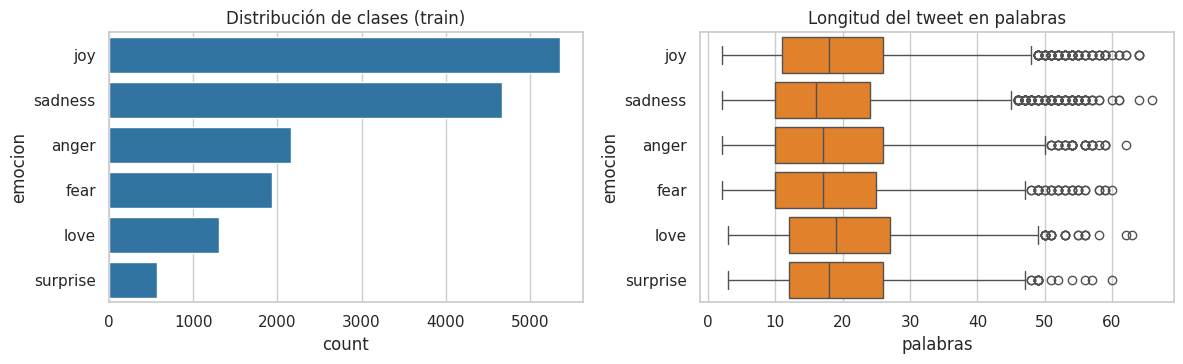

count    20000.0
mean        19.1
std         11.0
min          2.0
25%         11.0
50%         17.0
75%         25.0
max         66.0
Name: palabras, dtype: float64
Razón de desbalance (clase mayor / menor): 9.4


In [6]:
df_emo = pd.concat([ds_emo[s].to_pandas().assign(split=s) for s in ds_emo])
df_emo["emocion"] = df_emo["label"].map(id2label_emo)
df_emo["palabras"] = df_emo["text"].str.split().str.len()

dist = (df_emo.groupby(["split", "emocion"]).size().unstack(0)
        .loc[lambda d: d["train"].sort_values(ascending=False).index])
print((dist / dist.sum() * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
orden = dist.index.tolist()
sns.countplot(data=df_emo[df_emo.split == "train"], y="emocion", order=orden, ax=ax[0], color="tab:blue")
ax[0].set_title("Distribución de clases (train)")
sns.boxplot(data=df_emo[df_emo.split == "train"], y="emocion", x="palabras", order=orden, ax=ax[1], color="tab:orange")
ax[1].set_title("Longitud del tweet en palabras")
plt.tight_layout(); plt.show()

print(df_emo["palabras"].describe().round(1))
print("Razón de desbalance (clase mayor / menor):", round(dist["train"].max() / dist["train"].min(), 1))

In [7]:
for emo in NOMBRES_EMO:
    print(f"\n--- {emo} ---")
    for t in df_emo[(df_emo.split == "train") & (df_emo.emocion == emo)].sample(2, random_state=SEED)["text"]:
        print(" *", t)


--- sadness ---
 * im feeling so lousy they tried to cheer me up during school time and during choir practice
 * i feel highly disadvantaged

--- joy ---
 * i feel im rather innocent in that respect
 * im feeling quite adventurous and tried out those drinks that i just normally read through the pages of pocketbooks

--- love ---
 * i mean fuck i feel like i was way more considerate with customers and concerned about appearance and sanitiation snoozel pm but fine
 * i remember a couple of years ago i was feeling romantic and dreamy and asked him wonder if we ll celebrate our th anniversary

--- anger ---
 * i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
 * i feel frustrated sometimes with my mac lipsticks when i have to read names or open each of them to select shade

--- fear ---
 * i can feel the frantic beat of his heart but cookie s voice is surprisingly clear
 * i feel

In [8]:
VACIAS = set("i im a an the and to of in it that is was am be my me for on with as so but at this have like feel feeling just not very really about when what by do or are all its up from can more how get you t s m".split())
for emo in NOMBRES_EMO:
    palabras = df_emo[(df_emo.split == "train") & (df_emo.emocion == emo)]["text"].str.split().explode()
    top = palabras[~palabras.isin(VACIAS)].value_counts().head(10)
    print(f"{emo:9s}: {', '.join(top.index)}")

inicio = df_emo["text"].str.startswith(("i feel", "i am feeling", "im feeling")).mean()
print(f"\nTweets que empiezan con 'i feel' / 'i am feeling' / 'im feeling': {inicio:.1%}")

sadness  : because, been, know, myself, out, had, being, ive, if, would
joy      : because, time, will, out, now, if, they, been, know, make
love     : love, her, him, he, know, because, will, if, sweet, who
anger    : because, myself, being, if, time, been, know, out, little, people
fear     : because, little, bit, know, myself, if, been, out, people, had
surprise : amazed, impressed, overwhelmed, weird, surprised, curious, funny, shocked, strange, little

Tweets que empiezan con 'i feel' / 'i am feeling' / 'im feeling': 38.0%


**Observaciones del EDA**

- Clases desbalanceadas: `joy` y `sadness` suman el 62.7 % del train, mientras `surprise` es solo el 3.6 % (razón de desbalance 9.4). Por eso se reporta F1 macro y la muestra de la búsqueda de hiperparámetros es estratificada.
- El 38 % de los tweets empieza con «i feel», «i am feeling» o «im feeling». Las palabras más frecuentes de cada clase son casi todas palabras funcionales compartidas; solo `surprise` (amazed, impressed, shocked) y `love` (love, sweet) tienen vocabulario propio entre las más frecuentes. La señal suele estar en una o dos palabras emocionales del tweet.
- La confusión esperada está entre clases cercanas semánticamente: `joy` y `love`, `fear` y `surprise`.
- El texto viene en minúsculas, así que un modelo *uncased* es la elección natural. La mediana es de 17 palabras y 20 tokens por tweet; el máximo es 87 tokens, así que `max_length=128` no trunca nada.

## 1.3 Modelo y tokenización

**Modelo:** `distilbert-base-uncased` (Sanh et al., 2019). Es una versión destilada de BERT con 6 capas en lugar de 12: conserva cerca del 97 % del desempeño de BERT en GLUE con 40 % menos parámetros y entrena más rápido, lo que permite probar más configuraciones en la GPU de Colab. Al modelo se le agrega una capa lineal de clasificación sobre el token `[CLS]` que se entrena desde cero; el resto de pesos se ajusta (fine-tuning completo).

In [9]:
CKPT_CLS = "distilbert-base-uncased"
tok_cls = AutoTokenizer.from_pretrained(CKPT_CLS)

ejemplo = df_emo["text"].iloc[0]
print(ejemplo)
print(tok_cls.tokenize(ejemplo))

largos = [len(x) for x in tok_cls(df_emo[df_emo.split == "train"]["text"].tolist())["input_ids"]]
print("Tokens por tweet, percentiles 50/95/99/max:", np.percentile(largos, [50, 95, 99, 100]).astype(int))
MAX_LEN_CLS = 128

def tokenizar_cls(batch):
    return tok_cls(batch["text"], truncation=True, max_length=MAX_LEN_CLS)

ds_emo_tok = ds_emo.map(tokenizar_cls, batched=True, remove_columns=["text"])
collator_cls = DataCollatorWithPadding(tok_cls)

def metricas_cls(p):
    logits, labels = p
    pred = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, pred), "f1_macro": f1_score(labels, pred, average="macro")}

def nuevo_modelo_cls():
    return AutoModelForSequenceClassification.from_pretrained(
        CKPT_CLS, num_labels=len(NOMBRES_EMO), id2label=id2label_emo, label2id=label2id_emo)

print(f"Parámetros: {contar_parametros(nuevo_modelo_cls()):.1f} M")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

i didnt feel humiliated
['i', 'didn', '##t', 'feel', 'humiliated']
Tokens por tweet, percentiles 50/95/99/max: [20 45 57 87]


Map:   0%|          | 0/16000 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Parámetros: 67.0 M


## 1.4 Búsqueda de hiperparámetros

Se prueba una grilla de **learning rate × batch size** (4 × 2 = 8 corridas) con una muestra estratificada de 3 000 tweets de train, 2 épocas, y se evalúa en 1 000 tweets de validación. El resto de hiperparámetros queda fijo: AdamW, weight decay 0.01, warmup del 10 % y decaimiento lineal.

In [10]:
hp_train_cls = ds_emo_tok["train"].train_test_split(train_size=HP_N_TRAIN_CLS, stratify_by_column="label", seed=SEED)["train"]
hp_val_cls = ds_emo_tok["validation"].shuffle(seed=SEED).select(range(min(HP_N_VAL_CLS, len(ds_emo_tok["validation"]))))

def entrenar_cls(lr, batch):
    set_seed(SEED)
    trainer = Trainer(
        model=nuevo_modelo_cls(),
        args=args_entrenamiento("tmp/hp_cls", lr, batch, HP_EPOCAS_CLS, len(hp_train_cls)),
        train_dataset=hp_train_cls, eval_dataset=hp_val_cls,
        processing_class=tok_cls, data_collator=collator_cls, compute_metrics=metricas_cls,
    )
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    m = trainer.evaluate()
    return {"f1_macro": round(m["eval_f1_macro"], 4), "accuracy": round(m["eval_accuracy"], 4), "eval_loss": round(m["eval_loss"], 4)}

grid_cls = [{"lr": lr, "batch": b} for lr in GRID_LR for b in GRID_BATCH]
hp_cls = busqueda_grid("clasificacion", grid_cls, entrenar_cls)
hp_cls.sort_values("f1_macro", ascending=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[1/8] {'lr': 1e-05, 'batch': 16, 'f1_macro': 0.4258, 'accuracy': 0.678, 'eval_loss': 0.9461, 'minutos': 1.38}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[2/8] {'lr': 1e-05, 'batch': 32, 'f1_macro': 0.2315, 'accuracy': 0.567, 'eval_loss': 1.245, 'minutos': 0.66}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[3/8] {'lr': 3e-05, 'batch': 16, 'f1_macro': 0.8216, 'accuracy': 0.893, 'eval_loss': 0.3744, 'minutos': 0.71}


... (7 outputs left out)

[7/8] {'lr': 0.0001, 'batch': 16, 'f1_macro': 0.8814, 'accuracy': 0.91, 'eval_loss': 0.3073, 'minutos': 0.28}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[8/8] {'lr': 0.0001, 'batch': 32, 'f1_macro': 0.8695, 'accuracy': 0.902, 'eval_loss': 0.3083, 'minutos': 0.2}


,lr,batch,f1_macro,accuracy,eval_loss,minutos
6,0.00010,16,0.8814,0.910,0.3073,0.28
7,0.00010,32,0.8695,0.902,0.3083,0.20
4,0.00005,16,0.8610,0.906,0.2847,0.54
2,0.00003,16,0.8216,0.893,0.3744,0.71
5,0.00005,32,0.7742,0.878,0.3919,0.24
3,0.00003,32,0.6253,0.806,0.6181,0.43
0,0.00001,16,0.4258,0.678,0.9461,1.38
1,0.00001,32,0.2315,0.567,1.2450,0.66


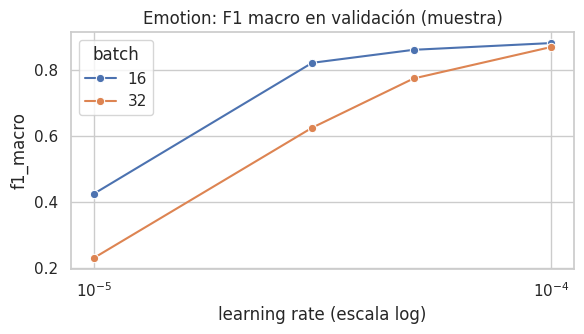

Mejor configuración: lr=0.0001, batch=16, F1 macro=0.8814


In [11]:
graficar_busqueda(hp_cls, "f1_macro", "Emotion: F1 macro en validación (muestra)")
mejor_cls = hp_cls.sort_values("f1_macro", ascending=False).iloc[0]
LR_CLS, BATCH_CLS = float(mejor_cls["lr"]), int(mejor_cls["batch"])
print(f"Mejor configuración: lr={LR_CLS}, batch={BATCH_CLS}, F1 macro={mejor_cls['f1_macro']}")

El learning rate fue lo que más movió la métrica: con 1e-5 el modelo apenas empieza a aprender en 2 épocas (F1 macro 0.43 con batch 16 y 0.23 con batch 32), mientras que con 1e-4 llega a 0.88. Con el mismo número de épocas, batch 16 superó a batch 32 en todos los learning rates, porque hace el doble de actualizaciones de pesos. El mejor valor quedó en el borde superior de la grilla (lr = 1e-4), así que valdría la pena probar valores un poco más altos.

## 1.5 Entrenamiento con el dataset completo

Con la mejor configuración se entrena sobre los 16 000 tweets, evaluando en validación al final de cada época y conservando el mejor checkpoint según F1 macro.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '1.723', 'grad_norm': '3.8', 'learning_rate': '1.633e-05', 'epoch': '0.05'}
{'loss': '1.464', 'grad_norm': '4.175', 'learning_rate': '3.3e-05', 'epoch': '0.1'}
{'loss': '0.9683', 'grad_norm': '6.387', 'learning_rate': '4.967e-05', 'epoch': '0.15'}
{'loss': '0.6254', 'grad_norm': '7.573', 'learning_rate': '6.633e-05', 'epoch': '0.2'}
{'loss': '0.5285', 'grad_norm': '2.478', 'learning_rate': '8.3e-05', 'epoch': '0.25'}
{'loss': '0.371', 'grad_norm': '14.45', 'learning_rate': '9.967e-05', 'epoch': '0.3'}
{'loss': '0.3565', 'grad_norm': '3.113', 'learning_rate': '9.819e-05', 'epoch': '0.35'}
{'loss': '0.3619', 'grad_norm': '27.59', 'learning_rate': '9.633e-05', 'epoch': '0.4'}
{'loss': '0.3594', 'grad_norm': '13.6', 'learning_rate': '9.448e-05', 'epoch': '0.45'}
{'loss': '0.3544', 'grad_norm': '1.377', 'learning_rate': '9.263e-05', 'epoch': '0.5'}
{'loss': '0.3309', 'grad_norm': '5.495', 'learning_rate': '9.078e-05', 'epoch': '0.55'}
{'loss': '0.2997', 'grad_norm': '28.9', 'learni

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1461', 'grad_norm': '1.026', 'learning_rate': '7.226e-05', 'epoch': '1.05'}
{'loss': '0.1339', 'grad_norm': '0.02485', 'learning_rate': '7.041e-05', 'epoch': '1.1'}
{'loss': '0.1818', 'grad_norm': '3.47', 'learning_rate': '6.856e-05', 'epoch': '1.15'}
{'loss': '0.1785', 'grad_norm': '3.242', 'learning_rate': '6.67e-05', 'epoch': '1.2'}
{'loss': '0.1455', 'grad_norm': '0.4571', 'learning_rate': '6.485e-05', 'epoch': '1.25'}
{'loss': '0.1542', 'grad_norm': '2.388', 'learning_rate': '6.3e-05', 'epoch': '1.3'}
{'loss': '0.1437', 'grad_norm': '2.786', 'learning_rate': '6.115e-05', 'epoch': '1.35'}
{'loss': '0.1352', 'grad_norm': '4.546', 'learning_rate': '5.93e-05', 'epoch': '1.4'}
{'loss': '0.1376', 'grad_norm': '0.6481', 'learning_rate': '5.744e-05', 'epoch': '1.45'}
{'loss': '0.16', 'grad_norm': '0.5677', 'learning_rate': '5.559e-05', 'epoch': '1.5'}
{'loss': '0.1356', 'grad_norm': '0.07092', 'learning_rate': '5.374e-05', 'epoch': '1.55'}
{'loss': '0.1229', 'grad_norm': '1.58

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1034', 'grad_norm': '0.02422', 'learning_rate': '3.522e-05', 'epoch': '2.05'}
{'loss': '0.08677', 'grad_norm': '1.54', 'learning_rate': '3.337e-05', 'epoch': '2.1'}
{'loss': '0.1112', 'grad_norm': '35.28', 'learning_rate': '3.152e-05', 'epoch': '2.15'}
{'loss': '0.0925', 'grad_norm': '9.728', 'learning_rate': '2.967e-05', 'epoch': '2.2'}
{'loss': '0.09156', 'grad_norm': '0.7661', 'learning_rate': '2.781e-05', 'epoch': '2.25'}
{'loss': '0.1308', 'grad_norm': '4.874', 'learning_rate': '2.596e-05', 'epoch': '2.3'}
{'loss': '0.1055', 'grad_norm': '1.616', 'learning_rate': '2.411e-05', 'epoch': '2.35'}
{'loss': '0.1103', 'grad_norm': '1.196', 'learning_rate': '2.226e-05', 'epoch': '2.4'}
{'loss': '0.09004', 'grad_norm': '1.624', 'learning_rate': '2.041e-05', 'epoch': '2.45'}
{'loss': '0.08942', 'grad_norm': '0.01042', 'learning_rate': '1.856e-05', 'epoch': '2.5'}
{'loss': '0.1244', 'grad_norm': '3.01', 'learning_rate': '1.67e-05', 'epoch': '2.55'}
{'loss': '0.07301', 'grad_norm'

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '144.6', 'train_samples_per_second': '331.9', 'train_steps_per_second': '20.74', 'train_loss': '0.2422', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento completo: 2.4 min


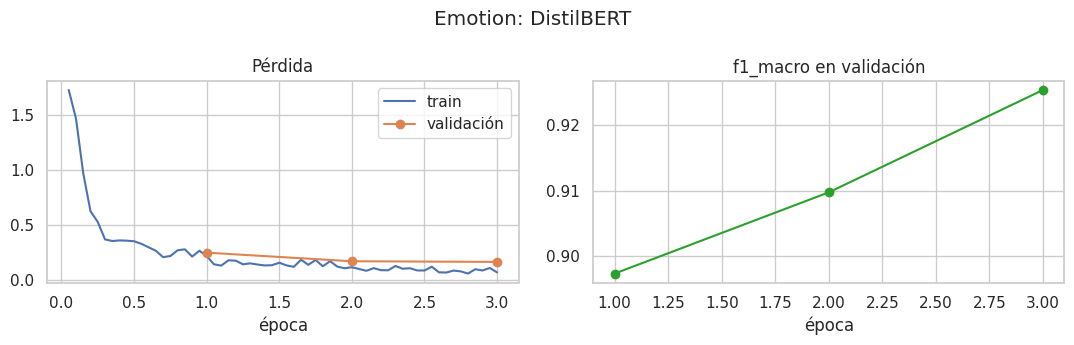

In [12]:
set_seed(SEED)
DIR_CLS = "modelos/emotion-distilbert"
trainer_cls = Trainer(
    model=nuevo_modelo_cls(),
    args=args_entrenamiento(DIR_CLS, LR_CLS, BATCH_CLS, EPOCAS_CLS, len(ds_emo_tok["train"]),
                            completo=True, metrica="f1_macro"),
    train_dataset=ds_emo_tok["train"], eval_dataset=ds_emo_tok["validation"],
    processing_class=tok_cls, data_collator=collator_cls, compute_metrics=metricas_cls,
)
t0 = time.time()
trainer_cls.train()
min_cls = (time.time() - t0) / 60
trainer_cls.save_model(DIR_CLS)
limpiar_checkpoints(DIR_CLS)
print(f"Entrenamiento completo: {min_cls:.1f} min")
graficar_curvas(trainer_cls, "f1_macro", "Emotion: DistilBERT")

## 1.6 Evaluación del mejor modelo en test

              precision    recall  f1-score   support

     sadness      0.968     0.976     0.972       581
         joy      0.954     0.945     0.949       695
        love      0.830     0.830     0.830       159
       anger      0.955     0.916     0.935       275
        fear      0.864     0.938     0.899       224
    surprise      0.814     0.727     0.768        66

    accuracy                          0.933      2000
   macro avg      0.897     0.889     0.892      2000
weighted avg      0.933     0.933     0.933      2000



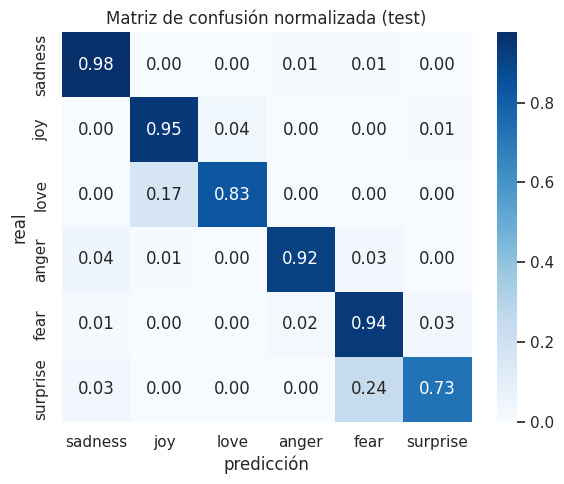

In [13]:
pred_test = trainer_cls.predict(ds_emo_tok["test"])
y_true = pred_test.label_ids
y_pred = pred_test.predictions.argmax(-1)
print(classification_report(y_true, y_pred, target_names=NOMBRES_EMO, digits=3))

cm = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=NOMBRES_EMO, yticklabels=NOMBRES_EMO)
plt.xlabel("predicción"); plt.ylabel("real"); plt.title("Matriz de confusión normalizada (test)")
plt.tight_layout(); plt.show()

RESULTADOS["Clasificación (Emotion)"] = {
    "modelo": CKPT_CLS, "lr": LR_CLS, "batch": BATCH_CLS, "épocas": EPOCAS_CLS,
    "métrica test": f"F1 macro = {f1_score(y_true, y_pred, average='macro'):.4f} | accuracy = {accuracy_score(y_true, y_pred):.4f}",
    "min. entrenamiento": round(min_cls, 1),
}

In [14]:
probs = torch.tensor(pred_test.predictions).softmax(-1).numpy()
errores = pd.DataFrame({
    "texto": list(ds_emo["test"]["text"]), "real": [NOMBRES_EMO[i] for i in y_true],
    "predicho": [NOMBRES_EMO[i] for i in y_pred], "confianza": probs.max(1).round(3),
}).query("real != predicho").sort_values("confianza", ascending=False)
print(f"Errores en test: {len(errores)} de {len(y_true)}")
errores.head(8)

Errores en test: 134 de 2000


,texto,real,predicho,confianza
1928,i feel inside cause life is like a game sometimes but then you came around me the walls just disappeared nothing to surround me and keep me from my fears im unprotected see how ive opened up youve...,fear,sadness,1.000
816,whenever i put myself in others shoes and try to make the person happy,anger,joy,1.000
193,i really dont like quinn because i feel like she will just end up hurting barney and i hated the lame ted robin storyline,anger,sadness,0.999
1000,i grew up around this feeling living only minutes away from the gorgeous atlantic ocean in brazil so its probably no surprise i grew fond of the ocean,joy,love,0.999
1555,i feel fucking woeful looking at the other girls,sadness,anger,0.999
1026,i have not conducted a survey but it is quite likely that many of them feel as assaulted by onel s demons and other creators as i would have felt had the walls been covered only with eminent figur...,sadness,fear,0.997
1146,i feel affirmed gracious sensuous and will have less self doubt when a href http generations,love,joy,0.997
131,im feeling generous today heres one more you may have already seen but is good for a chuckle,love,joy,0.996


Varios errores de alta confianza son discutibles: el tweet contiene palabras de la clase predicha y la etiqueta original viene de un hashtag que el autor eligió. Es una limitación conocida de la supervisión distante, no solo del modelo.

In [15]:
modelo_cls = trainer_cls.model.eval()

def predecir_emocion(textos):
    enc = tok_cls([t.lower() for t in textos], truncation=True, padding=True,
                  max_length=MAX_LEN_CLS, return_tensors="pt").to(modelo_cls.device)
    with torch.no_grad():
        p = modelo_cls(**enc).logits.softmax(-1).cpu().numpy()
    return pd.DataFrame({"texto": textos, "emoción": [NOMBRES_EMO[i] for i in p.argmax(1)],
                         "confianza": p.max(1).round(3)})

predecir_emocion([
    "I finally passed my thesis defense, I can't stop smiling",
    "I feel so alone since my best friend moved to another city",
    "I am terrified of the exam tomorrow",
    "I can't believe they gave me the job, I did not see that coming",
    "I love spending sundays with my family",
    "I am so angry that the bus left without me again",
])

,texto,emoción,confianza
0,"I finally passed my thesis defense, I can't stop smiling",joy,0.998
1,I feel so alone since my best friend moved to another city,sadness,1.000
2,I am terrified of the exam tomorrow,fear,1.000
3,"I can't believe they gave me the job, I did not see that coming",joy,0.976
4,I love spending sundays with my family,sadness,0.440
5,I am so angry that the bus left without me again,anger,1.000


**Análisis del mejor modelo**

- En test logra F1 macro de 0.892 y accuracy de 0.933 (134 errores de 2 000). En validación el F1 macro subió en cada época (0.897, 0.910 y 0.925), sin señales de sobreajuste en 3 épocas.
- Las clases con más tweets son las mejores: `sadness` 0.972, `joy` 0.949, `anger` 0.935. Las más difíciles son `surprise` (0.768, solo 66 ejemplos en test) y `love` (0.830), que se confunden con emociones cercanas.
- En las frases nuevas acierta joy, sadness, fear y anger con confianza alta. «I love spending sundays with my family» sale como sadness con confianza baja (0.44): una frase sin la estructura «i feel ...» del corpus le cuesta más. La del trabajo inesperado sale como joy, que también es razonable.

In [16]:
# El modelo queda en CPU por si se publica al final
modelo_cls.to("cpu")
del trainer_cls
liberar_memoria()

# 2. Etiquetado de secuencias: reconocimiento de entidades nombradas (NER)

## 2.1 Descripción del dataset

**Dataset:** CoNLL-2003 (Tjong Kim Sang y De Meulder, 2003), tarea compartida de NER independiente del idioma, parte en inglés.

- **Dominio:** noticias. Artículos de la agencia Reuters (corpus RCV1, agosto de 1996 a agosto de 1997).
- **Utilidad:** extracción de información (quién, qué organización, dónde), anonimización de documentos, indexación de noticias, enlace de entidades y como paso previo para sistemas de preguntas y respuestas.
- **Entrada:** una oración ya tokenizada en palabras.
- **Salida:** una etiqueta por palabra en esquema IOB2 con 4 tipos de entidad: `PER` (persona), `ORG` (organización), `LOC` (lugar) y `MISC` (miscelánea: nacionalidades, eventos, obras, etc.). `B-` marca el inicio de una entidad, `I-` su continuación y `O` las palabras fuera de entidad (9 etiquetas en total).
- **Tipo de problema:** etiquetado de secuencias (clasificación a nivel de token).
- **Tamaño:** 14 041 oraciones de train, 3 250 de validación y 3 453 de test.
- **Métrica:** F1 a nivel de entidad con `seqeval`: una entidad cuenta como acierto solo si el tipo y los límites coinciden exactamente. La accuracy por token es engañosa porque la mayoría de tokens son `O`.

Desde `datasets` 4.0 la versión con script de carga (`conll2003`) ya no funciona, así que se carga una copia en formato parquet con el mismo contenido.

In [17]:
ETIQUETAS_CONLL = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]

def cargar_conll():
    for repo in ["lhoestq/conll2003", "eriktks/conll2003", "lukasgarbas/conll-03"]:
        try:
            ds = load_dataset(repo)
            print("Cargado desde", repo)
            return ds
        except Exception as e:
            print(f"{repo}: {type(e).__name__}")
    raise RuntimeError("No se pudo cargar CoNLL-2003")

def normalizar_conll(ds):
    # Cada copia de CoNLL guarda las etiquetas distinto; se dejan como enteros en el orden de ETIQUETAS_CONLL
    interno = getattr(ds["train"].features["ner_tags"], "feature", None)
    if hasattr(interno, "names"):
        nombres = list(interno.names)
    else:
        muestra = next(t for t in list(ds["train"]["ner_tags"]) if len(t))
        if isinstance(muestra[0], str):
            vistos = {e for tags in list(ds["train"]["ner_tags"]) for e in tags}
            nombres = ETIQUETAS_CONLL if vistos <= set(ETIQUETAS_CONLL) else ["O"] + sorted(vistos - {"O"})
            ds = ds.map(lambda ex: {"ner_tags": [nombres.index(t) for t in ex["ner_tags"]]})
        else:
            nombres = ETIQUETAS_CONLL
    ds = ds.filter(lambda ex: len(ex["tokens"]) > 0 and ex["tokens"][0] != "-DOCSTART-")
    return DatasetDict({s: ds[s].select_columns(["tokens", "ner_tags"]) for s in ds}), nombres

ds_ner, NOMBRES_NER = normalizar_conll(cargar_conll())
id2label_ner = dict(enumerate(NOMBRES_NER))
label2id_ner = {v: k for k, v in id2label_ner.items()}
print(ds_ner)
print("Etiquetas:", NOMBRES_NER)

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

... (5 outputs left out)

Filter:   0%|          | 0/14041 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3250 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3453
    })
})
Etiquetas: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


## 2.2 Análisis exploratorio

            n_PER  n_ORG  n_LOC  n_MISC  oraciones
split                                             
test         1617   1661   1668     702       3453
train        6600   6321   7140    3438      14041
validation   1842   1341   1837     922       3250

Tokens etiquetados 'O' en train: 83.3%
Oraciones sin ninguna entidad: 20.5%


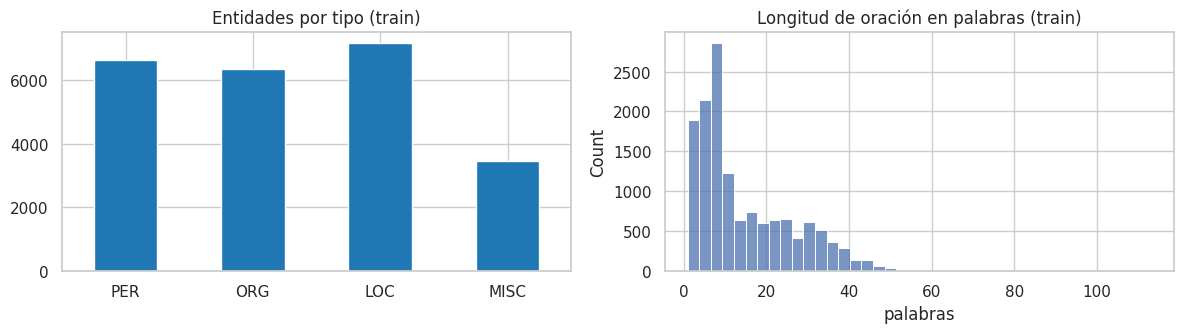

In [18]:
filas = []
for s in ds_ner:
    for tags in list(ds_ner[s]["ner_tags"]):
        et = [id2label_ner[t] for t in tags]
        ents = get_entities(et)
        filas.append({"split": s, "palabras": len(et), "entidades": len(ents),
                      **{f"n_{tipo}": sum(1 for e in ents if e[0] == tipo) for tipo in ["PER", "ORG", "LOC", "MISC"]}})
df_ner = pd.DataFrame(filas)

resumen = df_ner.groupby("split")[["n_PER", "n_ORG", "n_LOC", "n_MISC"]].sum()
resumen["oraciones"] = df_ner.groupby("split").size()
print(resumen)

tags_train = pd.Series([id2label_ner[t] for tags in list(ds_ner["train"]["ner_tags"]) for t in tags])
print(f"\nTokens etiquetados 'O' en train: {(tags_train == 'O').mean():.1%}")
print(f"Oraciones sin ninguna entidad: {(df_ner.entidades == 0).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
resumen.loc["train", ["n_PER", "n_ORG", "n_LOC", "n_MISC"]].rename(lambda x: x[2:]).plot.bar(ax=ax[0], color="tab:blue", rot=0)
ax[0].set_title("Entidades por tipo (train)")
sns.histplot(df_ner[df_ner.split == "train"]["palabras"], bins=40, ax=ax[1])
ax[1].set_title("Longitud de oración en palabras (train)")
plt.tight_layout(); plt.show()

In [19]:
def mostrar_oracion(i, split="train"):
    ex = ds_ner[split][i]
    display(pd.DataFrame([ex["tokens"], [id2label_ner[t] for t in ex["ner_tags"]]], index=["palabra", "etiqueta"]))

con_varias = df_ner[(df_ner.split == "train") & (df_ner[["n_PER", "n_ORG", "n_LOC", "n_MISC"]].gt(0).sum(1) >= 3)].index[:2]
for i in con_varias:
    mostrar_oracion(int(i))

,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
palabra,Germany,'s,representative,to,the,European,Union,'s,veterinary,committee,...,other,than,Britain,until,the,scientific,advice,was,clearer,.
etiqueta,B-LOC,O,O,O,O,B-ORG,I-ORG,O,O,O,...,O,O,B-LOC,O,O,O,O,O,O,O


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
palabra,Fischler,proposed,EU-wide,measures,after,reports,from,Britain,and,France,...,Spongiform,Encephalopathy,(,BSE,),--,mad,cow,disease,.
etiqueta,B-PER,O,B-MISC,O,O,O,O,B-LOC,O,B-LOC,...,I-MISC,I-MISC,O,B-MISC,O,O,O,O,O,O


**Observaciones del EDA**

- Cerca del 83 % de los tokens son `O`: un modelo que siempre prediga `O` tendría alta accuracy por token y F1 de entidades igual a cero. De ahí la métrica de seqeval.
- `MISC` es la clase más heterogénea (nacionalidades, eventos deportivos, idiomas) y suele ser la más difícil. Las confusiones típicas son `ORG` y `LOC` con nombres de países o ciudades que actúan como equipos deportivos, muy comunes en las noticias de Reuters.
- Muchas oraciones son muy cortas (resultados deportivos, encabezados), y otras tienen más de 40 palabras.

## 2.3 Modelo, tokenización y alineación de etiquetas

**Modelo:** `bert-base-cased` (Devlin et al., 2019), 12 capas y 110 M de parámetros. Se usa la versión *cased* porque las mayúsculas son una señal fuerte para reconocer nombres propios. Se agrega una capa lineal que clasifica cada token en una de las 9 etiquetas.

BERT trabaja con subpalabras (WordPiece), mientras las etiquetas están por palabra. Se asigna la etiqueta de la palabra a su **primer subtoken** y se marca con `-100` el resto de subtokens y los tokens especiales para que la función de pérdida los ignore. En la predicción se toma también el primer subtoken de cada palabra.

In [20]:
CKPT_NER = "bert-base-cased"
tok_ner = AutoTokenizer.from_pretrained(CKPT_NER)

def tokenizar_y_alinear(batch):
    enc = tok_ner(batch["tokens"], truncation=True, is_split_into_words=True, max_length=MAX_LEN_NER)
    etiquetas = []
    for i, tags in enumerate(batch["ner_tags"]):
        previo, fila = None, []
        for w in enc.word_ids(i):
            fila.append(-100 if w is None or w == previo else tags[w])
            previo = w
        etiquetas.append(fila)
    enc["labels"] = etiquetas
    return enc

largos = [len(x) for x in tok_ner(list(ds_ner["train"]["tokens"]), is_split_into_words=True)["input_ids"]]
print("Subtokens por oración, percentiles 50/95/99/max:", np.percentile(largos, [50, 95, 99, 100]).astype(int))
MAX_LEN_NER = 256

ex = ds_ner["train"][int(con_varias[0])]
enc = tokenizar_y_alinear({"tokens": [ex["tokens"]], "ner_tags": [ex["ner_tags"]]})
display(pd.DataFrame({
    "subtoken": tok_ner.convert_ids_to_tokens(enc["input_ids"][0]),
    "palabra": ["-" if w is None else w for w in enc.word_ids(0)],
    "etiqueta": [id2label_ner.get(l, "-100") if l != -100 else "-100" for l in enc["labels"][0]],
}).T)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Subtokens por oración, percentiles 50/95/99/max: [ 17  47  58 173]


,0,1,2,3,4,5,6,7,8,9,...,29,30,31,32,33,34,35,36,37,38
subtoken,[CLS],Germany,',s,representative,to,the,European,Union,',...,than,Britain,until,the,scientific,advice,was,clearer,.,[SEP]
palabra,-,0,1,1,2,3,4,5,6,7,...,22,23,24,25,26,27,28,29,30,-
etiqueta,-100,B-LOC,O,-100,O,O,O,B-ORG,I-ORG,O,...,O,B-LOC,O,O,O,O,O,O,O,-100


In [21]:
ds_ner_tok = ds_ner.map(tokenizar_y_alinear, batched=True, remove_columns=["tokens", "ner_tags"])
collator_ner = DataCollatorForTokenClassification(tok_ner)

def a_etiquetas(pred, labels):
    y_true, y_pred = [], []
    for p, l in zip(pred, labels):
        mascara = l != -100
        y_true.append([id2label_ner[int(x)] for x in l[mascara]])
        y_pred.append([id2label_ner[int(x)] for x in p[mascara]])
    return y_true, y_pred

def metricas_ner(p):
    logits, labels = p
    y_true, y_pred = a_etiquetas(np.argmax(logits, -1), labels)
    return {"f1": seq_f1(y_true, y_pred), "precision": seq_precision(y_true, y_pred),
            "recall": seq_recall(y_true, y_pred), "accuracy": seq_accuracy(y_true, y_pred)}

def nuevo_modelo_ner():
    return AutoModelForTokenClassification.from_pretrained(
        CKPT_NER, num_labels=len(NOMBRES_NER), id2label=id2label_ner, label2id=label2id_ner)

print(f"Parámetros: {contar_parametros(nuevo_modelo_ner()):.1f} M")

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Parámetros: 107.7 M


## 2.4 Búsqueda de hiperparámetros

Misma grilla que en clasificación (learning rate × batch size), con 3 000 oraciones de train, 2 épocas y 1 000 oraciones de validación. Se elige por F1 de entidades.

In [22]:
hp_train_ner = ds_ner_tok["train"].shuffle(seed=SEED).select(range(min(HP_N_TRAIN_NER, len(ds_ner_tok["train"]))))
hp_val_ner = ds_ner_tok["validation"].shuffle(seed=SEED).select(range(min(HP_N_VAL_NER, len(ds_ner_tok["validation"]))))

def entrenar_ner(lr, batch):
    set_seed(SEED)
    trainer = Trainer(
        model=nuevo_modelo_ner(),
        args=args_entrenamiento("tmp/hp_ner", lr, batch, HP_EPOCAS_NER, len(hp_train_ner)),
        train_dataset=hp_train_ner, eval_dataset=hp_val_ner,
        processing_class=tok_ner, data_collator=collator_ner, compute_metrics=metricas_ner,
    )
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    m = trainer.evaluate()
    return {"f1": round(m["eval_f1"], 4), "precision": round(m["eval_precision"], 4),
            "recall": round(m["eval_recall"], 4), "eval_loss": round(m["eval_loss"], 4)}

grid_ner = [{"lr": lr, "batch": b} for lr in GRID_LR for b in GRID_BATCH]
hp_ner = busqueda_grid("ner", grid_ner, entrenar_ner)
hp_ner.sort_values("f1", ascending=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[1/8] {'lr': 1e-05, 'batch': 16, 'f1': 0.8181, 'precision': 0.808, 'recall': 0.8283, 'eval_loss': 0.1068, 'minutos': 0.46}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[2/8] {'lr': 1e-05, 'batch': 32, 'f1': 0.6513, 'precision': 0.6341, 'recall': 0.6695, 'eval_loss': 0.1855, 'minutos': 0.35}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[3/8] {'lr': 3e-05, 'batch': 16, 'f1': 0.8926, 'precision': 0.8845, 'recall': 0.9008, 'eval_loss': 0.0584, 'minutos': 0.47}


... (7 outputs left out)

[7/8] {'lr': 0.0001, 'batch': 16, 'f1': 0.925, 'precision': 0.9215, 'recall': 0.9287, 'eval_loss': 0.0492, 'minutos': 0.47}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[8/8] {'lr': 0.0001, 'batch': 32, 'f1': 0.9102, 'precision': 0.9052, 'recall': 0.9153, 'eval_loss': 0.0509, 'minutos': 0.34}


,lr,batch,f1,precision,recall,eval_loss,minutos
6,0.00010,16,0.9250,0.9215,0.9287,0.0492,0.47
4,0.00005,16,0.9171,0.9123,0.9220,0.0507,0.47
7,0.00010,32,0.9102,0.9052,0.9153,0.0509,0.34
5,0.00005,32,0.8933,0.8908,0.8958,0.0608,0.34
2,0.00003,16,0.8926,0.8845,0.9008,0.0584,0.47
3,0.00003,32,0.8686,0.8659,0.8712,0.0727,0.34
0,0.00001,16,0.8181,0.8080,0.8283,0.1068,0.46
1,0.00001,32,0.6513,0.6341,0.6695,0.1855,0.35


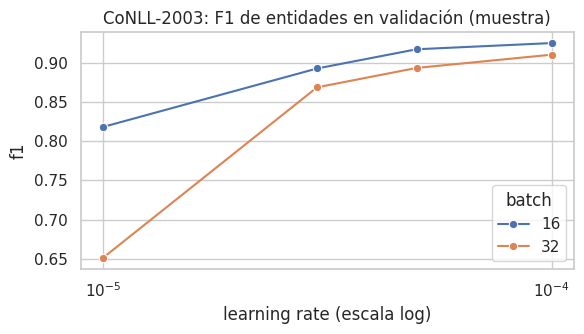

Mejor configuración: lr=0.0001, batch=16, F1=0.925


In [23]:
graficar_busqueda(hp_ner, "f1", "CoNLL-2003: F1 de entidades en validación (muestra)")
mejor_ner = hp_ner.sort_values("f1", ascending=False).iloc[0]
LR_NER, BATCH_NER = float(mejor_ner["lr"]), int(mejor_ner["batch"])
print(f"Mejor configuración: lr={LR_NER}, batch={BATCH_NER}, F1={mejor_ner['f1']}")

Mismo patrón que en clasificación: con lr = 1e-5 el F1 queda en 0.82 (batch 16) y 0.65 (batch 32), y con 1e-4 llega a 0.925. Batch 16 vuelve a ganar en todos los casos. El rango entre learning rates es menor que en clasificación (0.18 frente a 0.55): incluso con el valor más bajo BERT ya reconoce buena parte de las entidades.

## 2.5 Entrenamiento con el dataset completo

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.407', 'grad_norm': '1.801', 'learning_rate': '1.863e-05', 'epoch': '0.05695'}
{'loss': '0.2994', 'grad_norm': '2.491', 'learning_rate': '3.764e-05', 'epoch': '0.1139'}
{'loss': '0.1208', 'grad_norm': '1.75', 'learning_rate': '5.665e-05', 'epoch': '0.1708'}
{'loss': '0.1086', 'grad_norm': '2.953', 'learning_rate': '7.567e-05', 'epoch': '0.2278'}
{'loss': '0.1016', 'grad_norm': '1.901', 'learning_rate': '9.468e-05', 'epoch': '0.2847'}
{'loss': '0.08865', 'grad_norm': '2.272', 'learning_rate': '9.848e-05', 'epoch': '0.3417'}
{'loss': '0.0684', 'grad_norm': '1.634', 'learning_rate': '9.637e-05', 'epoch': '0.3986'}
{'loss': '0.07671', 'grad_norm': '2.572', 'learning_rate': '9.426e-05', 'epoch': '0.4556'}
{'loss': '0.07906', 'grad_norm': '1.827', 'learning_rate': '9.216e-05', 'epoch': '0.5125'}
{'loss': '0.07822', 'grad_norm': '2.039', 'learning_rate': '9.005e-05', 'epoch': '0.5695'}
{'loss': '0.0478', 'grad_norm': '8.977', 'learning_rate': '8.794e-05', 'epoch': '0.6264'}
{'loss'

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.03857', 'grad_norm': '0.9388', 'learning_rate': '7.318e-05', 'epoch': '1.025'}
{'loss': '0.03479', 'grad_norm': '0.6381', 'learning_rate': '7.107e-05', 'epoch': '1.082'}
{'loss': '0.02936', 'grad_norm': '1.077', 'learning_rate': '6.896e-05', 'epoch': '1.139'}
{'loss': '0.03275', 'grad_norm': '0.1994', 'learning_rate': '6.685e-05', 'epoch': '1.196'}
{'loss': '0.02607', 'grad_norm': '2.216', 'learning_rate': '6.474e-05', 'epoch': '1.253'}
{'loss': '0.03267', 'grad_norm': '0.3914', 'learning_rate': '6.263e-05', 'epoch': '1.31'}
{'loss': '0.02624', 'grad_norm': '2.324', 'learning_rate': '6.052e-05', 'epoch': '1.367'}
{'loss': '0.02485', 'grad_norm': '0.4039', 'learning_rate': '5.841e-05', 'epoch': '1.424'}
{'loss': '0.03437', 'grad_norm': '0.1527', 'learning_rate': '5.631e-05', 'epoch': '1.481'}
{'loss': '0.0325', 'grad_norm': '0.2488', 'learning_rate': '5.42e-05', 'epoch': '1.538'}
{'loss': '0.03142', 'grad_norm': '0.2885', 'learning_rate': '5.209e-05', 'epoch': '1.595'}
{'los

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.01259', 'grad_norm': '0.1378', 'learning_rate': '3.522e-05', 'epoch': '2.05'}
{'loss': '0.006924', 'grad_norm': '0.007891', 'learning_rate': '3.311e-05', 'epoch': '2.107'}
{'loss': '0.01214', 'grad_norm': '0.2088', 'learning_rate': '3.1e-05', 'epoch': '2.164'}
{'loss': '0.01019', 'grad_norm': '1.435', 'learning_rate': '2.889e-05', 'epoch': '2.221'}
{'loss': '0.009416', 'grad_norm': '2.086', 'learning_rate': '2.678e-05', 'epoch': '2.278'}
{'loss': '0.005952', 'grad_norm': '0.8568', 'learning_rate': '2.467e-05', 'epoch': '2.335'}
{'loss': '0.01217', 'grad_norm': '0.4999', 'learning_rate': '2.256e-05', 'epoch': '2.392'}
{'loss': '0.005784', 'grad_norm': '0.01016', 'learning_rate': '2.046e-05', 'epoch': '2.449'}
{'loss': '0.008121', 'grad_norm': '0.1947', 'learning_rate': '1.835e-05', 'epoch': '2.506'}
{'loss': '0.009036', 'grad_norm': '0.01305', 'learning_rate': '1.624e-05', 'epoch': '2.563'}
{'loss': '0.005977', 'grad_norm': '0.227', 'learning_rate': '1.413e-05', 'epoch': '2.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '361.6', 'train_samples_per_second': '116.5', 'train_steps_per_second': '7.284', 'train_loss': '0.06635', 'epoch': '3'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento completo: 6.0 min


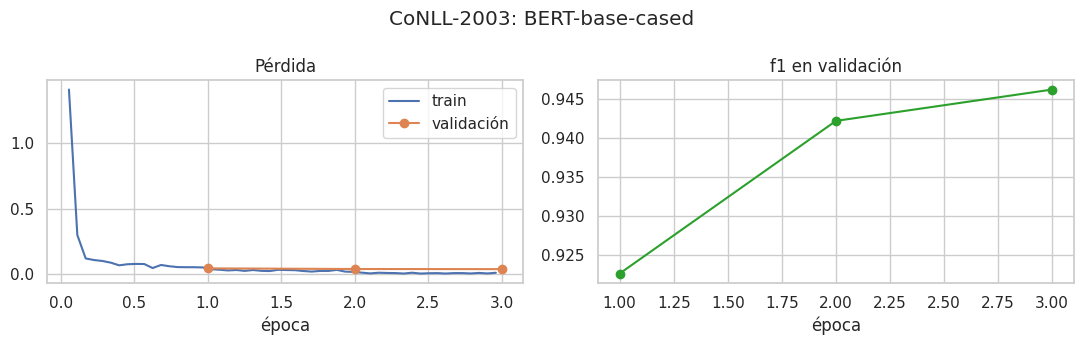

In [24]:
set_seed(SEED)
DIR_NER = "modelos/conll2003-bert-ner"
trainer_ner = Trainer(
    model=nuevo_modelo_ner(),
    args=args_entrenamiento(DIR_NER, LR_NER, BATCH_NER, EPOCAS_NER, len(ds_ner_tok["train"]),
                            completo=True, metrica="f1"),
    train_dataset=ds_ner_tok["train"], eval_dataset=ds_ner_tok["validation"],
    processing_class=tok_ner, data_collator=collator_ner, compute_metrics=metricas_ner,
)
t0 = time.time()
trainer_ner.train()
min_ner = (time.time() - t0) / 60
trainer_ner.save_model(DIR_NER)
limpiar_checkpoints(DIR_NER)
print(f"Entrenamiento completo: {min_ner:.1f} min")
graficar_curvas(trainer_ner, "f1", "CoNLL-2003: BERT-base-cased")

## 2.6 Evaluación del mejor modelo en test

In [25]:
pred_ner = trainer_ner.predict(ds_ner_tok["test"])
y_true_ner, y_pred_ner = a_etiquetas(pred_ner.predictions.argmax(-1), pred_ner.label_ids)
print(seq_report(y_true_ner, y_pred_ner, digits=3))
f1_ner_test = seq_f1(y_true_ner, y_pred_ner)

RESULTADOS["Etiquetado (CoNLL-2003 NER)"] = {
    "modelo": CKPT_NER, "lr": LR_NER, "batch": BATCH_NER, "épocas": EPOCAS_NER,
    "métrica test": f"F1 entidades = {f1_ner_test:.4f} | precision = {seq_precision(y_true_ner, y_pred_ner):.4f} | recall = {seq_recall(y_true_ner, y_pred_ner):.4f}",
    "min. entrenamiento": round(min_ner, 1),
}

              precision    recall  f1-score   support

         LOC      0.933     0.929     0.931      1668
        MISC      0.775     0.819     0.796       702
         ORG      0.863     0.914     0.887      1661
         PER      0.965     0.940     0.952      1617

   micro avg      0.900     0.914     0.907      5648
   macro avg      0.884     0.900     0.892      5648
weighted avg      0.902     0.914     0.907      5648



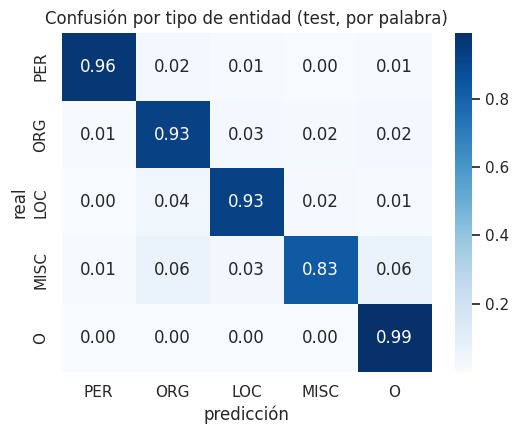

In [26]:
# Sin prefijo B/I para comparar por tipo de entidad
tipo = lambda e: e.split("-")[-1]
plano_true = [tipo(e) for s in y_true_ner for e in s]
plano_pred = [tipo(e) for s in y_pred_ner for e in s]
clases = ["PER", "ORG", "LOC", "MISC", "O"]
cm = confusion_matrix(plano_true, plano_pred, labels=clases, normalize="true")
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=clases, yticklabels=clases)
plt.xlabel("predicción"); plt.ylabel("real"); plt.title("Confusión por tipo de entidad (test, por palabra)")
plt.tight_layout(); plt.show()

In [27]:
palabras_test = list(ds_ner["test"]["tokens"])
con_error = [i for i, (t, p) in enumerate(zip(y_true_ner, y_pred_ner)) if t != p and 6 <= len(t) <= 20]
print(f"Oraciones con al menos un error: {sum(t != p for t, p in zip(y_true_ner, y_pred_ner))} de {len(y_true_ner)}")
for i in con_error[:3]:
    display(pd.DataFrame([palabras_test[i], y_true_ner[i], y_pred_ner[i]], index=["palabra", "real", "predicho"]))

Oraciones con al menos un error: 498 de 3453


,0,1,2,3,4,5,6,7,8,9,10,11
palabra,SOCCER,-,JAPAN,GET,LUCKY,WIN,",",CHINA,IN,SURPRISE,DEFEAT,.
real,O,O,B-LOC,O,O,O,O,B-PER,O,O,O,O
predicho,O,O,B-MISC,O,B-PER,O,O,B-ORG,O,O,O,O


,0,1,2,3,4,5,6,7,8,9,10
palabra,RUGBY,UNION,-,CUTTITTA,BACK,FOR,ITALY,AFTER,A,YEAR,.
real,B-ORG,I-ORG,O,B-PER,O,O,B-LOC,O,O,O,O
predicho,B-ORG,I-ORG,O,B-ORG,O,O,B-ORG,O,O,O,O


,0,1,2,3,4,5,6,7,8,9
palabra,SOCCER,-,LATE,GOALS,GIVE,JAPAN,WIN,OVER,SYRIA,.
real,O,O,O,O,O,B-LOC,O,O,B-LOC,O
predicho,O,O,O,O,O,B-ORG,O,O,O,O


In [28]:
modelo_ner = trainer_ner.model.eval()

def extraer_entidades(texto):
    palabras = re.findall(r"\w+(?:[-'.]\w+)*|[^\w\s]", texto)
    enc = tok_ner(palabras, is_split_into_words=True, truncation=True, return_tensors="pt")
    ids_palabra = enc.word_ids()
    with torch.no_grad():
        pred = modelo_ner(**enc.to(modelo_ner.device)).logits[0].argmax(-1).tolist()
    etiquetas, previo = [], None
    for k, w in enumerate(ids_palabra):
        if w is not None and w != previo:
            etiquetas.append(id2label_ner[pred[k]])
        previo = w
    return [(" ".join(palabras[a:b + 1]), t) for t, a, b in get_entities(etiquetas)]

for frase in [
    "Brayan Ramirez studies Systems Engineering at the University of Antioquia in Medellin.",
    "Shakira performed in Barranquilla before flying to Miami with Sony Music executives.",
    "The European Central Bank raised interest rates, said Christine Lagarde in Frankfurt.",
    "Atletico Nacional beat Millonarios 2-1 in the Colombian league final.",
]:
    print(frase, "\n   ->", extraer_entidades(frase))

Brayan Ramirez studies Systems Engineering at the University of Antioquia in Medellin. 
   -> [('Brayan Ramirez', 'PER'), ('Systems Engineering', 'ORG'), ('University of Antioquia', 'ORG'), ('Medellin', 'LOC')]
Shakira performed in Barranquilla before flying to Miami with Sony Music executives. 
   -> [('Shakira', 'PER'), ('Barranquilla', 'LOC'), ('Miami', 'LOC'), ('Sony Music', 'ORG')]
The European Central Bank raised interest rates, said Christine Lagarde in Frankfurt. 
   -> [('European Central Bank', 'ORG'), ('Christine Lagarde', 'PER'), ('Frankfurt', 'LOC')]
Atletico Nacional beat Millonarios 2-1 in the Colombian league final. 
   -> [('Atletico Nacional', 'ORG'), ('Millonarios', 'ORG'), ('Colombian', 'MISC')]


**Análisis del mejor modelo**

- F1 de entidades en test = 0.907 (precision 0.900, recall 0.914). En validación llegó a 0.946 en la tercera época. La caída en test es conocida en CoNLL-2003: el test son noticias de diciembre de 1996, posteriores a las de train, con muchas entidades que el modelo no vio.
- Por tipo: `PER` es la mejor (0.952), seguida de `LOC` (0.931) y `ORG` (0.887). `MISC` es la más difícil (0.796), como se esperaba en el EDA.
- Los errores mostrados son titulares deportivos en mayúsculas: sin la pista de las mayúsculas el modelo duda entre país (`LOC`) y selección nacional (`ORG`). Hay además etiquetas discutibles en el propio dataset, como `CHINA` marcado como persona.
- En las frases nuevas reconoce personas, ciudades y organizaciones colombianas que no aparecen en el corpus. El único error es marcar «Systems Engineering» como organización.

In [29]:
modelo_ner.to("cpu")
del trainer_ner
liberar_memoria()

# 3. Secuencia a secuencia: resumen abstractivo de diálogos

## 3.1 Descripción del dataset

**Dataset:** [`knkarthick/dialogsum`](https://huggingface.co/datasets/knkarthick/dialogsum), copia en CSV de DialogSum (Chen et al., 2021, *DialogSum: A Real-Life Scenario Dialogue Summarization Dataset*, Findings of ACL).

- **Dominio:** conversaciones cotidianas en inglés entre dos o más personas: citas médicas, compras, entrevistas de trabajo, trámites, viajes, conversaciones entre amigos. Los hablantes aparecen como `#Person1#`, `#Person2#`, etc.
- **Utilidad:** generar actas de reuniones o llamadas, resumir conversaciones de atención al cliente, notas de consultas, resumen de chats largos.
- **Entrada:** el diálogo completo (varias intervenciones separadas por saltos de línea).
- **Salida:** un resumen corto escrito por anotadores, en tercera persona y en lenguaje formal, que conserva las entidades importantes.
- **Tipo de problema:** secuencia a secuencia, resumen **abstractivo** (el modelo redacta texto nuevo, no copia frases).
- **Tamaño:** 12 460 diálogos de train, 500 de validación y 500 de test. En esta copia el archivo de test tiene 1 500 filas porque cada diálogo de test trae **tres resúmenes de referencia** de anotadores distintos. Incluye además la columna `topic` (tema en pocas palabras).
- **Licencia:** CC BY-NC-SA 4.0.
- **Métrica:** ROUGE-1, ROUGE-2 y ROUGE-L (F1 de coincidencia de unigramas, bigramas y de la subsecuencia común más larga entre resumen generado y referencia). En test se toma, para cada diálogo, el mejor puntaje frente a sus tres referencias.

In [30]:
ds_sum = load_dataset("knkarthick/dialogsum",
                      data_files={"train": "train.csv", "validation": "validation.csv", "test": "test.csv"})
ds_sum = ds_sum.filter(lambda ex: bool(ex["dialogue"]) and bool(ex["summary"]))
print(ds_sum)

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

... (2 outputs left out)

Filter:   0%|          | 0/12460 [00:00<?, ? examples/s]

Filter:   0%|          | 0/500 [00:00<?, ? examples/s]

Filter:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


## 3.2 Análisis exploratorio

            palabras_dialogo  palabras_resumen  turnos  compresion
split                                                             
test                   120.0              17.0     9.0         7.1
train                  116.0              21.0     9.0         5.5
validation             115.0              18.0     9.0         5.9

Diálogos únicos en test: 500 (filas: 1500)


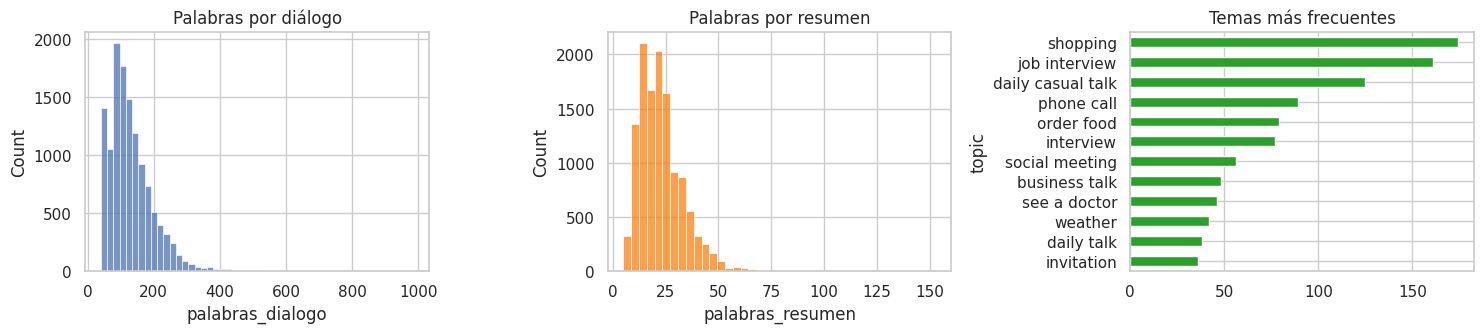

In [31]:
df_sum = pd.concat([ds_sum[s].to_pandas().assign(split=s) for s in ds_sum])
df_sum["palabras_dialogo"] = df_sum["dialogue"].str.split().str.len()
df_sum["palabras_resumen"] = df_sum["summary"].str.split().str.len()
df_sum["turnos"] = df_sum["dialogue"].str.count(r"#Person\d+#:")
df_sum["compresion"] = df_sum["palabras_dialogo"] / df_sum["palabras_resumen"]

print(df_sum.groupby("split")[["palabras_dialogo", "palabras_resumen", "turnos", "compresion"]].median().round(1))
test_unicos = df_sum[df_sum.split == "test"]["dialogue"].nunique()
print(f"\nDiálogos únicos en test: {test_unicos} (filas: {(df_sum.split == 'test').sum()})")

tr = df_sum[df_sum.split == "train"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(tr["palabras_dialogo"], bins=50, ax=ax[0]); ax[0].set_title("Palabras por diálogo")
sns.histplot(tr["palabras_resumen"], bins=40, ax=ax[1], color="tab:orange"); ax[1].set_title("Palabras por resumen")
tr["topic"].value_counts().head(12)[::-1].plot.barh(ax=ax[2], color="tab:green"); ax[2].set_title("Temas más frecuentes")
plt.tight_layout(); plt.show()

In [32]:
for _, fila in tr.sample(2, random_state=SEED).iterrows():
    print(f"TEMA: {fila['topic']}\n\nDIÁLOGO:\n{fila['dialogue']}\n\nRESUMEN DE REFERENCIA:\n{fila['summary']}\n" + "-" * 90)

TEMA: new job

DIÁLOGO:
#Person1#: I heard you had got a wonderful job in a post office. How's your new job going?
#Person2#: Not so well, I'm afraid. I just feel like a fish out of water. People there are rather strange to me.

RESUMEN DE REFERENCIA:
#Person2# does not like the new job.
------------------------------------------------------------------------------------------
TEMA: outdoor activities

DIÁLOGO:
#Person1#: Mr. Lin, what are you interested in?
#Person2#: I enjoy camping.
#Person1#: Really? I'm not much of an outdoor person. What do you like about it?
#Person2#: I love the fresh air, the scenery the exercise, and the time to think.
#Person1#: Do you hike or fish on your trips?
#Person2#: Yes, both. Last trip I fished a little and hiked five miles.
#Person1#: Did you catch anything?
#Person2#: Yes, but I threw them back.
#Person1#: How about Joining our summer camp next week?
#Person2#: Great! I can't wait.

RESUMEN DE REFERENCIA:
Mr. Lin tells #Person1# he enjoys camping,

**Observaciones del EDA**

- La mediana es de 9 intervenciones y 116 palabras por diálogo, con resúmenes de 21 palabras: una compresión cercana a 5.5:1.
- Los resúmenes cambian la perspectiva: pasan de primera y segunda persona («I», «you») a tercera persona con los marcadores de hablante («#Person1# asks #Person2#...»). Por eso no basta con extraer frases del diálogo y se necesita un modelo generativo.
- Los temas son muy variados, lo que exige generalización y no memorizar plantillas.

## 3.3 Modelo y tokenización

**Modelo:** `facebook/bart-base` (Lewis et al., 2020), encoder-decoder de 6 + 6 capas y unos 140 M de parámetros. Se preentrenó como autoencoder con ruido (reconstruir texto corrupto), lo que lo hace adecuado para generación condicionada como el resumen. El encoder lee el diálogo y el decoder genera el resumen token a token, atendiendo al encoder con *cross-attention*.

Se eligió BART-base y no T5 porque entrena de forma estable en precisión mixta (fp16) en la T4 de Colab. T5 es propenso a desbordes numéricos (NaN) en fp16 y tendría que entrenarse en fp32, que es más lento.

In [33]:
CKPT_SUM = "facebook/bart-base"
tok_sum = AutoTokenizer.from_pretrained(CKPT_SUM)

lar_in = [len(x) for x in tok_sum(list(ds_sum["train"]["dialogue"]))["input_ids"]]
lar_out = [len(x) for x in tok_sum(list(ds_sum["train"]["summary"]))["input_ids"]]
print("Tokens del diálogo, percentiles 50/95/99/max:", np.percentile(lar_in, [50, 95, 99, 100]).astype(int))
print("Tokens del resumen, percentiles 50/95/99/max:", np.percentile(lar_out, [50, 95, 99, 100]).astype(int))
MAX_IN, MAX_OUT = 512, 128
print(f"Diálogos que se truncan con MAX_IN={MAX_IN}: {np.mean(np.array(lar_in) > MAX_IN):.2%}")

def preprocesar_sum(batch):
    enc = tok_sum(batch["dialogue"], max_length=MAX_IN, truncation=True)
    enc["labels"] = tok_sum(text_target=batch["summary"], max_length=MAX_OUT, truncation=True)["input_ids"]
    return enc

ds_sum_tok = DatasetDict({s: ds_sum[s].map(preprocesar_sum, batched=True, remove_columns=ds_sum[s].column_names)
                          for s in ["train", "validation"]})

def nuevo_modelo_sum():
    return AutoModelForSeq2SeqLM.from_pretrained(CKPT_SUM)

print(f"Parámetros: {contar_parametros(nuevo_modelo_sum()):.1f} M")

config.json:   0%|          | 0.00/1.72k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokens del diálogo, percentiles 50/95/99/max: [ 193  390  578 1429]
Tokens del resumen, percentiles 50/95/99/max: [ 34  64  84 249]
Diálogos que se truncan con MAX_IN=512: 1.52%


Map:   0%|          | 0/12460 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

Parámetros: 139.4 M


In [34]:
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL", "rougeLsum"], use_stemmer=True)

def con_saltos(t):
    # rougeLsum compara frase a frase, separadas por salto de línea
    return "\n".join(re.split(r"(?<=[.!?])\s+", t.strip()))

def calcular_rouge(predicciones, referencias):
    # Admite una o varias referencias por ejemplo
    tot = {k: [] for k in ["rouge1", "rouge2", "rougeL", "rougeLsum"]}
    for p, refs in zip(predicciones, referencias):
        refs = [refs] if isinstance(refs, str) else refs
        punt = [scorer.score(con_saltos(r), con_saltos(p)) for r in refs]
        for k in tot:
            tot[k].append(max(s[k].fmeasure for s in punt))
    return {k: round(100 * float(np.mean(v)), 2) for k, v in tot.items()}

def generar_resumenes(modelo, textos, batch=16, num_beams=4):
    modelo.eval()
    salidas = []
    for i in range(0, len(textos), batch):
        enc = tok_sum(textos[i:i + batch], max_length=MAX_IN, truncation=True, padding=True, return_tensors="pt").to(modelo.device)
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=FP16):
            out = modelo.generate(**enc, num_beams=num_beams, max_new_tokens=MAX_OUT, early_stopping=num_beams > 1)
        salidas += tok_sum.batch_decode(out, skip_special_tokens=True)
    return [s.strip() for s in salidas]

### Línea base sin fine-tuning

Antes de ajustar se evalúa `bart-base` tal como viene. Como solo fue preentrenado para reconstruir texto, tiende a copiar el diálogo en lugar de resumirlo. Esto sirve de referencia para medir lo que aporta el fine-tuning.

In [35]:
val_dialogos = list(ds_sum["validation"]["dialogue"])
val_resumenes = list(ds_sum["validation"]["summary"])

modelo_base = nuevo_modelo_sum().to(DEVICE)
pred_base = generar_resumenes(modelo_base, val_dialogos[:100], num_beams=1)
rouge_base = calcular_rouge(pred_base, val_resumenes[:100])
print("ROUGE bart-base sin ajustar (100 diálogos de validación):", rouge_base)
print("\nEjemplo de salida:\n", pred_base[0][:400])
del modelo_base; liberar_memoria()

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

ROUGE bart-base sin ajustar (100 diálogos de validación): {'rouge1': 22.34, 'rouge2': 6.73, 'rougeL': 16.85, 'rougeLsum': 20.34}

Ejemplo de salida:
 #Person1#: Hello, how are you doing today?#Person2#: I ' ve been having trouble breathing lately. I just have a heavy feeling in my chest when I try to breathe.#Person3#: Have you had any type of cold lately?# Person2#?#PTSD: No, I haven ' t had a cold. I have a very heavy feeling when I tried to breathe, but I can 't.#PSTD: What is your asthma?#MRS#Person 1#: Do you have any allergies that you kn


## 3.4 Búsqueda de hiperparámetros

En seq2seq cada corrida es más costosa (generar texto para evaluar es lento), así que se fija el batch en 8 y se prueban 4 learning rates con 2 000 diálogos de train y 2 épocas. Cada modelo se evalúa generando resúmenes para 200 diálogos de validación con búsqueda voraz (*greedy*) y calculando ROUGE. Se elige por ROUGE-L.

In [36]:
hp_train_sum = ds_sum_tok["train"].shuffle(seed=SEED).select(range(min(HP_N_TRAIN_SUM, len(ds_sum_tok["train"]))))
hp_val_sum = ds_sum_tok["validation"].select(range(min(HP_N_VAL_SUM, len(ds_sum_tok["validation"]))))

def entrenar_sum(lr, batch):
    set_seed(SEED)
    modelo = nuevo_modelo_sum()
    trainer = Seq2SeqTrainer(
        model=modelo,
        args=args_entrenamiento("tmp/hp_sum", lr, batch, HP_EPOCAS_SUM, len(hp_train_sum), seq2seq=True),
        train_dataset=hp_train_sum, eval_dataset=hp_val_sum,
        processing_class=tok_sum, data_collator=DataCollatorForSeq2Seq(tok_sum, model=modelo),
    )
    trainer.remove_callback(PrinterCallback)
    trainer.train()
    perdida = trainer.evaluate()["eval_loss"]
    pred = generar_resumenes(trainer.model, val_dialogos[:len(hp_val_sum)], num_beams=1)
    r = calcular_rouge(pred, val_resumenes[:len(hp_val_sum)])
    return {"rougeL": r["rougeL"], "rouge1": r["rouge1"], "rouge2": r["rouge2"], "eval_loss": round(perdida, 4)}

grid_sum = [{"lr": lr, "batch": BATCH_SUM} for lr in GRID_LR_SUM]
hp_sum = busqueda_grid("resumen", grid_sum, entrenar_sum)
hp_sum.sort_values("rougeL", ascending=False)

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

[1/4] {'lr': 2e-05, 'batch': 8, 'rougeL': 35.36, 'rouge1': 44.64, 'rouge2': 17.62, 'eval_loss': 1.2954, 'minutos': 1.4}


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

[2/4] {'lr': 5e-05, 'batch': 8, 'rougeL': 36.33, 'rouge1': 45.38, 'rouge2': 19.07, 'eval_loss': 1.2585, 'minutos': 1.41}


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

[3/4] {'lr': 0.0001, 'batch': 8, 'rougeL': 35.93, 'rouge1': 44.26, 'rouge2': 18.42, 'eval_loss': 1.2556, 'minutos': 1.48}


Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

[4/4] {'lr': 0.0002, 'batch': 8, 'rougeL': 36.63, 'rouge1': 44.99, 'rouge2': 18.97, 'eval_loss': 1.3165, 'minutos': 1.4}


,lr,batch,rougeL,rouge1,rouge2,eval_loss,minutos
3,0.00020,8,36.63,44.99,18.97,1.3165,1.40
1,0.00005,8,36.33,45.38,19.07,1.2585,1.41
2,0.00010,8,35.93,44.26,18.42,1.2556,1.48
0,0.00002,8,35.36,44.64,17.62,1.2954,1.40


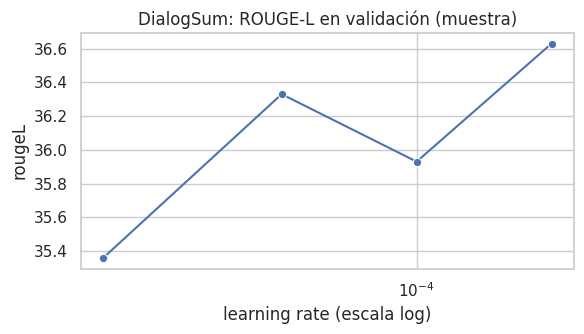

Mejor configuración: lr=0.0002, batch=8, ROUGE-L=36.63


In [37]:
graficar_busqueda(hp_sum, "rougeL", "DialogSum: ROUGE-L en validación (muestra)")
mejor_sum = hp_sum.sort_values("rougeL", ascending=False).iloc[0]
LR_SUM = float(mejor_sum["lr"])
print(f"Mejor configuración: lr={LR_SUM}, batch={BATCH_SUM}, ROUGE-L={mejor_sum['rougeL']}")

Aquí el learning rate casi no cambió el resultado: ROUGE-L entre 35.4 y 36.6, una diferencia pequeña para una muestra de 200 diálogos evaluada con búsqueda voraz. Se tomó lr = 2e-4 por tener el ROUGE-L más alto, aunque tuvo la mayor pérdida de validación; lr = 5e-5 habría sido una elección igual de razonable.

## 3.5 Entrenamiento con el dataset completo

Se entrena sobre los 12 460 diálogos. En cada época se calcula la pérdida de validación y se conserva el mejor checkpoint según esa pérdida (calcular ROUGE en cada época haría el entrenamiento mucho más lento).

Loading weights:   0%|          | 0/259 [00:00<?, ?it/s]

{'loss': '2.613', 'grad_norm': '7.552', 'learning_rate': '1.573e-05', 'epoch': '0.03209'}
{'loss': '1.756', 'grad_norm': '6.656', 'learning_rate': '3.178e-05', 'epoch': '0.06418'}
{'loss': '1.616', 'grad_norm': '7.12', 'learning_rate': '4.783e-05', 'epoch': '0.09628'}
{'loss': '1.666', 'grad_norm': '6.108', 'learning_rate': '6.388e-05', 'epoch': '0.1284'}
{'loss': '1.632', 'grad_norm': '6.665', 'learning_rate': '7.994e-05', 'epoch': '0.1605'}
{'loss': '1.651', 'grad_norm': '7.386', 'learning_rate': '9.599e-05', 'epoch': '0.1926'}
{'loss': '1.639', 'grad_norm': '5.707', 'learning_rate': '0.000112', 'epoch': '0.2246'}
{'loss': '1.628', 'grad_norm': '5.181', 'learning_rate': '0.0001281', 'epoch': '0.2567'}
{'loss': '1.591', 'grad_norm': '5.642', 'learning_rate': '0.0001441', 'epoch': '0.2888'}
{'loss': '1.629', 'grad_norm': '7.452', 'learning_rate': '0.0001602', 'epoch': '0.3209'}
{'loss': '1.628', 'grad_norm': '4.716', 'learning_rate': '0.0001762', 'epoch': '0.353'}
{'loss': '1.715', 'gr

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.357', 'grad_norm': '5.124', 'learning_rate': '0.0001652', 'epoch': '1.027'}
{'loss': '1.335', 'grad_norm': '3.975', 'learning_rate': '0.0001634', 'epoch': '1.059'}
{'loss': '1.297', 'grad_norm': '5.149', 'learning_rate': '0.0001616', 'epoch': '1.091'}
{'loss': '1.316', 'grad_norm': '4.516', 'learning_rate': '0.0001599', 'epoch': '1.123'}
{'loss': '1.33', 'grad_norm': '4.358', 'learning_rate': '0.0001581', 'epoch': '1.155'}
{'loss': '1.324', 'grad_norm': '4.431', 'learning_rate': '0.0001563', 'epoch': '1.187'}
{'loss': '1.307', 'grad_norm': '5.211', 'learning_rate': '0.0001545', 'epoch': '1.22'}
{'loss': '1.305', 'grad_norm': '11.57', 'learning_rate': '0.0001527', 'epoch': '1.252'}
{'loss': '1.307', 'grad_norm': '4.475', 'learning_rate': '0.0001509', 'epoch': '1.284'}
{'loss': '1.297', 'grad_norm': '4.011', 'learning_rate': '0.0001492', 'epoch': '1.316'}
{'loss': '1.319', 'grad_norm': '5.129', 'learning_rate': '0.0001474', 'epoch': '1.348'}
{'loss': '1.312', 'grad_norm': '4.

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '1.054', 'grad_norm': '4.602', 'learning_rate': '0.0001099', 'epoch': '2.022'}
{'loss': '0.9475', 'grad_norm': '79.48', 'learning_rate': '0.0001081', 'epoch': '2.054'}
{'loss': '1', 'grad_norm': '3.386', 'learning_rate': '0.0001064', 'epoch': '2.086'}
{'loss': '0.9722', 'grad_norm': '3.917', 'learning_rate': '0.0001046', 'epoch': '2.118'}
{'loss': '0.9634', 'grad_norm': '3.099', 'learning_rate': '0.0001028', 'epoch': '2.15'}
{'loss': '0.9927', 'grad_norm': '4.085', 'learning_rate': '0.000101', 'epoch': '2.182'}
{'loss': '0.9544', 'grad_norm': '3.879', 'learning_rate': '9.923e-05', 'epoch': '2.214'}
{'loss': '0.9591', 'grad_norm': '3.877', 'learning_rate': '9.745e-05', 'epoch': '2.246'}
{'loss': '0.9747', 'grad_norm': '3.666', 'learning_rate': '9.567e-05', 'epoch': '2.279'}
{'loss': '1.002', 'grad_norm': '4.267', 'learning_rate': '9.388e-05', 'epoch': '2.311'}
{'loss': '0.9809', 'grad_norm': '4.041', 'learning_rate': '9.21e-05', 'epoch': '2.343'}
{'loss': '0.9695', 'grad_norm':

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '1308', 'train_samples_per_second': '38.09', 'train_steps_per_second': '4.763', 'train_loss': '1.153', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entrenamiento completo: 21.9 min


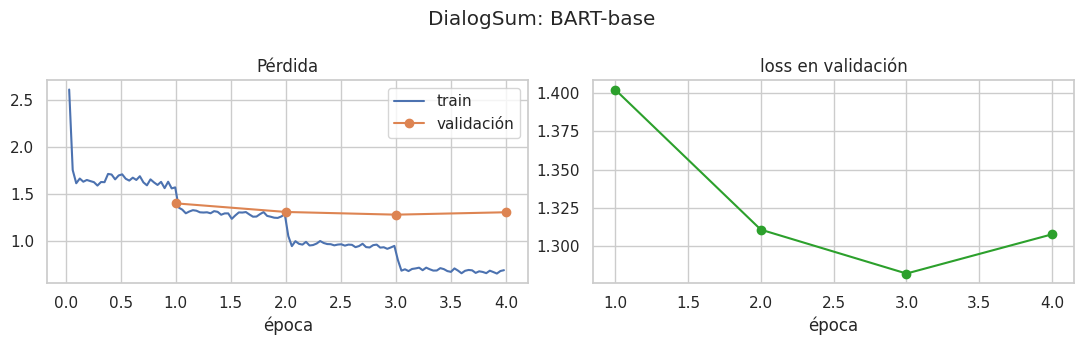

In [38]:
set_seed(SEED)
DIR_SUM = "modelos/dialogsum-bart-base"
modelo = nuevo_modelo_sum()
trainer_sum = Seq2SeqTrainer(
    model=modelo,
    args=args_entrenamiento(DIR_SUM, LR_SUM, BATCH_SUM, EPOCAS_SUM, len(ds_sum_tok["train"]),
                            seq2seq=True, completo=True, metrica="eval_loss", mayor_mejor=False),
    train_dataset=ds_sum_tok["train"], eval_dataset=ds_sum_tok["validation"],
    processing_class=tok_sum, data_collator=DataCollatorForSeq2Seq(tok_sum, model=modelo),
)
t0 = time.time()
trainer_sum.train()
min_sum = (time.time() - t0) / 60
trainer_sum.save_model(DIR_SUM)
limpiar_checkpoints(DIR_SUM)
print(f"Entrenamiento completo: {min_sum:.1f} min")
graficar_curvas(trainer_sum, "loss", "DialogSum: BART-base")

## 3.6 Evaluación del mejor modelo en test

In [39]:
modelo_sum = trainer_sum.model.eval()

pred_val = generar_resumenes(modelo_sum, val_dialogos, num_beams=4)
print("ROUGE validación (500 diálogos, beam=4):", calcular_rouge(pred_val, val_resumenes))

# Cada diálogo de test tiene tres referencias
test_df = ds_sum["test"].to_pandas()
test_agr = test_df.groupby("dialogue", sort=False)["summary"].apply(list).reset_index()
print(f"Diálogos de test: {len(test_agr)} | referencias por diálogo: {test_agr['summary'].str.len().value_counts().to_dict()}")

t0 = time.time()
pred_test_sum = generar_resumenes(modelo_sum, test_agr["dialogue"].tolist(), num_beams=4)
rouge_test = calcular_rouge(pred_test_sum, test_agr["summary"].tolist())
print(f"ROUGE test (multi-referencia, beam=4): {rouge_test}  [{(time.time() - t0) / 60:.1f} min]")

comparacion = pd.DataFrame([
    {"modelo": "bart-base sin ajustar (100 val)", **rouge_base},
    {"modelo": "bart-base ajustado (500 val)", **calcular_rouge(pred_val, val_resumenes)},
    {"modelo": "bart-base ajustado (500 test, multi-ref)", **rouge_test},
])
display(comparacion)

RESULTADOS["Seq2seq (DialogSum)"] = {
    "modelo": CKPT_SUM, "lr": LR_SUM, "batch": BATCH_SUM, "épocas": EPOCAS_SUM,
    "métrica test": f"ROUGE-1 = {rouge_test['rouge1']} | ROUGE-2 = {rouge_test['rouge2']} | ROUGE-L = {rouge_test['rougeL']}",
    "min. entrenamiento": round(min_sum, 1),
}

ROUGE validación (500 diálogos, beam=4): {'rouge1': 47.88, 'rouge2': 23.05, 'rougeL': 40.07, 'rougeLsum': 43.15}
Diálogos de test: 500 | referencias por diálogo: {3: 500}
ROUGE test (multi-referencia, beam=4): {'rouge1': 51.48, 'rouge2': 26.55, 'rougeL': 43.14, 'rougeLsum': 46.48}  [0.7 min]


,modelo,rouge1,rouge2,rougeL,rougeLsum
0,bart-base sin ajustar (100 val),22.34,6.73,16.85,20.34
1,bart-base ajustado (500 val),47.88,23.05,40.07,43.15
2,"bart-base ajustado (500 test, multi-ref)",51.48,26.55,43.14,46.48


In [40]:
largo_gen = pd.Series(pred_test_sum).str.split().str.len()
largo_ref = test_agr["summary"].apply(lambda r: np.mean([len(x.split()) for x in r]))
print(f"Palabras por resumen: generado {largo_gen.median():.0f} | referencia {largo_ref.median():.0f} (medianas)")

for i in [k for k in (0, 7, 42) if k < len(test_agr)]:
    print(f"DIÁLOGO:\n{test_agr['dialogue'][i]}\n")
    print(f"REFERENCIA 1: {test_agr['summary'][i][0]}")
    print(f"GENERADO:     {pred_test_sum[i]}\n" + "-" * 90)

Palabras por resumen: generado 22 | referencia 17 (medianas)
DIÁLOGO:
#Person1#: Ms. Dawson, I need you to take a dictation for me.
#Person2#: Yes, sir...
#Person1#: This should go out as an intra-office memorandum to all employees by this afternoon. Are you ready?
#Person2#: Yes, sir. Go ahead.
#Person1#: Attention all staff... Effective immediately, all office communications are restricted to email correspondence and official memos. The use of Instant Message programs by employees during working hours is strictly prohibited.
#Person2#: Sir, does this apply to intra-office communications only? Or will it also restrict external communications?
#Person1#: It should apply to all communications, not only in this office between employees, but also any outside communications.
#Person2#: But sir, many employees use Instant Messaging to communicate with their clients.
#Person1#: They will just have to change their communication methods. I don't want any - one using Instant Messaging in this o

In [41]:
dialogo_nuevo = '''#Person1#: Hi, I'm calling because my internet has been down since yesterday morning.
#Person2#: I'm sorry to hear that. Can you give me your account number?
#Person1#: Sure, it's 4 5 7 2 1. I work from home, so this is really urgent.
#Person2#: I see there is an outage in your neighborhood. A technician is already working on it.
#Person1#: Do you know when it will be fixed?
#Person2#: It should be back by 3 pm today. I'll also add a discount to your next bill for the inconvenience.
#Person1#: Thank you, that helps.'''
print(generar_resumenes(modelo_sum, [dialogo_nuevo])[0])

#Person1# calls #Person2# because the internet has been down since yesterday morning. They will be back by 3 pm today.


**Análisis del mejor modelo**

- El fine-tuning lleva ROUGE-L de 16.9 (`bart-base` sin ajustar, que solo copia el diálogo) a 40.1 en validación y 43.1 en test. El test sale más alto porque cada diálogo se compara contra la mejor de sus tres referencias.
- La pérdida de validación bajó hasta la época 3 (1.282) y subió en la 4 (1.308), una primera señal de sobreajuste; por eso se conservó el checkpoint de la época 3.
- Los resúmenes generados son algo más largos que las referencias (mediana de 22 palabras frente a 17) y tienden a copiar frases del diálogo.
- Los ejemplos muestran errores que ROUGE no castiga: inventa un hablante que no existe (`#Person3#`), produce un marcador mal formado (`#Person1ll`) y en el diálogo de empleos dice que `#Person2#` quiere ser director de noticias cuando dice lo contrario. El resumen del diálogo nuevo de soporte técnico sí es correcto.

# 4. Resumen de resultados

Mejor modelo encontrado para cada problema, con los hiperparámetros elegidos en la búsqueda y su desempeño en el conjunto de test.

In [42]:
tabla = pd.DataFrame(RESULTADOS).T
tabla.to_csv("resultados/resumen_resultados.csv")
tabla

,modelo,lr,batch,épocas,métrica test,min. entrenamiento
Clasificación (Emotion),distilbert-base-uncased,0.0001,16,3,F1 macro = 0.8923 | accuracy = 0.9330,2.4
Etiquetado (CoNLL-2003 NER),bert-base-cased,0.0001,16,3,F1 entidades = 0.9067 | precision = 0.8996 | recall = 0.9140,6.0
Seq2seq (DialogSum),facebook/bart-base,0.0002,8,4,ROUGE-1 = 51.48 | ROUGE-2 = 26.55 | ROUGE-L = 43.14,21.9


In [43]:
for nombre, df, m in [("Clasificación", hp_cls, "f1_macro"), ("NER", hp_ner, "f1"), ("Resumen", hp_sum, "rougeL")]:
    por_lr = df.groupby("lr")[m].mean()
    texto = f"{nombre:13s} | {m}: rango al variar lr = {por_lr.max() - por_lr.min():.4f} (mejor lr {por_lr.idxmax()})"
    if df["batch"].nunique() > 1:
        por_b = df.groupby("batch")[m].mean()
        texto += f" | rango al variar batch = {por_b.max() - por_b.min():.4f}"
    print(texto)

Clasificación | f1_macro: rango al variar lr = 0.5468 (mejor lr 0.0001) | rango al variar batch = 0.1223
NER           | f1: rango al variar lr = 0.1829 (mejor lr 0.0001) | rango al variar batch = 0.0574
Resumen       | rougeL: rango al variar lr = 1.2700 (mejor lr 0.0002)


**Conclusiones**

| Tarea | Mejor configuración | Resultado en test |
|---|---|---|
| Emotion (DistilBERT) | lr = 1e-4, batch = 16, 3 épocas | F1 macro = 0.892, accuracy = 0.933 |
| CoNLL-2003 NER (BERT-base-cased) | lr = 1e-4, batch = 16, 3 épocas | F1 entidades = 0.907 (P = 0.900, R = 0.914) |
| DialogSum (BART-base) | lr = 2e-4, batch = 8, 4 épocas (mejor en la 3) | ROUGE-1 = 51.5, ROUGE-2 = 26.6, ROUGE-L = 43.1 |

- En las tres tareas se partió de un modelo preentrenado de forma general y solo cambió la cabeza de salida y el formato de los datos: una etiqueta por texto, una etiqueta por token o una secuencia nueva. En resumen se ve el efecto con claridad: ROUGE-L pasa de 16.9 sin ajustar a 43.1 en test.
- El learning rate fue el hiperparámetro decisivo en clasificación y NER. En la búsqueda, pasar de 1e-5 a 1e-4 subió el F1 macro de 0.43 a 0.88 y el F1 de entidades de 0.82 a 0.93: con un learning rate bajo el modelo no alcanza a converger en 2 épocas. En ambos casos el mejor valor quedó en el borde superior de la grilla, así que el siguiente paso sería probar valores mayores.
- Con el número de épocas fijo, batch 16 superó a batch 32 en las 8 comparaciones, porque hace el doble de actualizaciones de pesos.
- En resumen el learning rate casi no movió ROUGE-L (1.3 puntos entre el peor y el mejor), una diferencia pequeña para 200 diálogos evaluados con búsqueda voraz.
- Los errores se concentran en lo menos frecuente o más ambiguo: `surprise` y `love` en emociones, `MISC` y los titulares en mayúsculas en NER, y la fidelidad al diálogo en el resumen.
- Limitaciones: los tres datasets están en inglés; las etiquetas de Emotion provienen de hashtags y tienen ruido; ROUGE mide coincidencia de palabras y no detecta errores de contenido como los vistos en los ejemplos; la búsqueda usó muestras, 2 épocas y una sola semilla.

## 5. Guardar los modelos (opcional)

Colab borra los archivos al cerrar la sesión. Estas celdas copian los modelos a Google Drive o los publican en el Hub de Hugging Face con la cuenta creada para la práctica.

In [45]:
GUARDAR_EN_DRIVE = True
if GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    destino = "/content/drive/MyDrive/PLN_Practica2"
    shutil.copytree("modelos", f"{destino}/modelos", dirs_exist_ok=True)
    shutil.copytree("resultados", f"{destino}/resultados", dirs_exist_ok=True)
    print("Copiado en", destino)

Mounted at /content/drive
Copiado en /content/drive/MyDrive/PLN_Practica2


In [46]:
SUBIR_AL_HUB = True
USUARIO_HF = "anonymous-666"
if SUBIR_AL_HUB:
    from huggingface_hub import login
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception:
        from getpass import getpass
        token = getpass("Token de Hugging Face (hf_...): ")
    login(token=token)
    for modelo, tok, nombre in [(modelo_cls, tok_cls, "distilbert-emotion"),
                                (modelo_ner, tok_ner, "bert-base-cased-conll2003-ner"),
                                (modelo_sum, tok_sum, "bart-base-dialogsum")]:
        modelo.push_to_hub(f"{USUARIO_HF}/{nombre}")
        tok.push_to_hub(f"{USUARIO_HF}/{nombre}")
        print("Publicado:", f"https://huggingface.co/{USUARIO_HF}/{nombre}")

Token de Hugging Face (hf_...): ··········


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...e3o_bkr/model.safetensors:   0%|          |  575kB /  268MB            

Validating                    :           |   0%            

... (12 outputs left out)

  ...du7g224/model.safetensors:   0%|          |  131kB /  558MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Publicado: https://huggingface.co/anonymous-666/bart-base-dialogsum
